# VolatilityQuant | Feature 4 — Historical Stress Testing

**Purpose:** Compare historical SPY market stress, five-day volatility forecasts, and model errors across the 2008, 2020, and 2022 stress windows. Run cells top to bottom in Google Colab. This notebook is an exploratory historical forecasting backtest, **not** a historical options-hedging backtest.

**Addition:** Section 3b scores each stress window's **resilience** — how deep the drawdown went, how long recovery took, how strongly prices rebounded, and how quickly volatility normalized — on a fixed 0–100 scale.

## 1. Setup and historical prices
Download adjusted SPY closing prices, calculate daily log returns and 20-day rolling annualized volatility.

In [1]:
import platform
print(platform.machine())

import xgboost as xgb
print(xgb.__version__)

arm64
3.4.1


In [2]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Use SPY as our market benchmark
ticker = "SPY"

# Download data covering major market crises
start_date = "2005-01-01"
end_date = "2026-10-01"

data = yf.download(
    ticker,
    start=start_date,
    end=end_date,
    auto_adjust=True,
    progress=False
)

if data.empty:
    raise ValueError("No market data downloaded.")

# Handle yfinance column formatting
if isinstance(data.columns, pd.MultiIndex):
    data.columns = data.columns.get_level_values(0)

# Adjusted closing prices
prices = data["Close"].dropna()

# Calculate daily log returns
returns = np.log(
    prices / prices.shift(1)
).dropna()

# Calculate annualized 20-day volatility
volatility = (
    returns.rolling(20).std()
    * np.sqrt(252)
    * 100
)

print("Stock:", ticker)
print("Trading days:", len(prices))
print("Start date:", prices.index.min().date())
print("End date:", prices.index.max().date())

display(data.head())

Stock: SPY
Trading days: 5470
Start date: 2005-01-03
End date: 2026-09-30


Price,Close,High,Low,Open,Volume
Date,,,,,
2005-01-03,80.973549,81.956270,80.704309,81.821647,55748000
2005-01-04,79.984062,81.135057,79.721555,81.081208,69167600
2005-01-05,79.432137,80.266775,79.425404,79.923494,65667300
2005-01-06,79.836014,80.199487,79.600431,79.721589,47814700
2005-01-07,79.721581,80.253328,79.512917,80.078321,55847700


## 2. Define stress windows and visualize volatility
Highlighted dates are selected research windows, not mechanically detected crises.

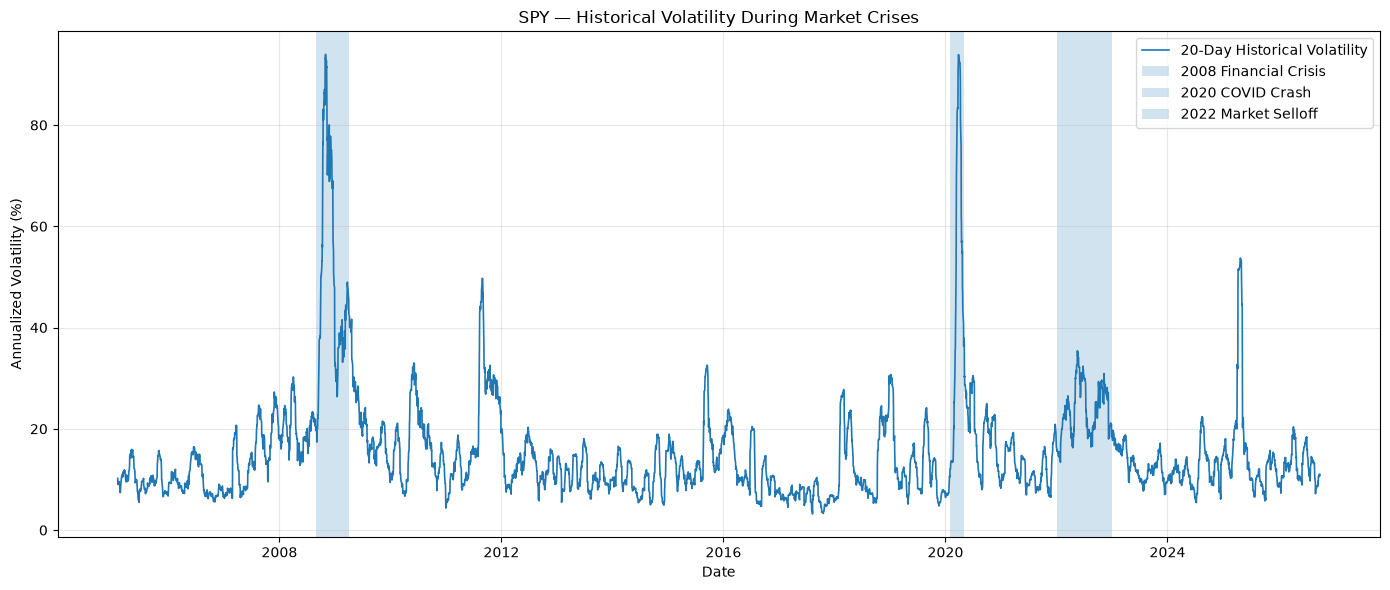

In [3]:
import matplotlib.pyplot as plt
import pandas as pd

# Define historical market stress periods
stress_periods = {
    "2008 Financial Crisis": (
        "2008-09-01", "2009-03-31"
    ),
    "2020 COVID Crash": (
        "2020-02-01", "2020-04-30"
    ),
    "2022 Market Selloff": (
        "2022-01-01", "2022-12-31"
    )
}

# Plot historical volatility
plt.figure(figsize=(14, 6))

plt.plot(
    volatility.index,
    volatility,
    label="20-Day Historical Volatility",
    linewidth=1.2
)

# Highlight stress periods
for name, (start, end) in stress_periods.items():

    plt.axvspan(
        pd.Timestamp(start),
        pd.Timestamp(end),
        alpha=0.20,
        label=name
    )

plt.title("SPY — Historical Volatility During Market Crises")
plt.xlabel("Date")
plt.ylabel("Annualized Volatility (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Market drawdowns
Drawdown is measured against the running peak since the beginning of the full downloaded series, not the peak within each crisis window.

,Crisis,Period Return (%),Peak Volatility (%),Average Volatility (%),Worst Drawdown (%)
0,2008 Financial Crisis,-36.55,93.97,51.65,-55.19
1,2020 COVID Crash,-9.85,93.92,50.56,-33.72
2,2022 Market Selloff,-18.65,35.41,23.72,-24.50


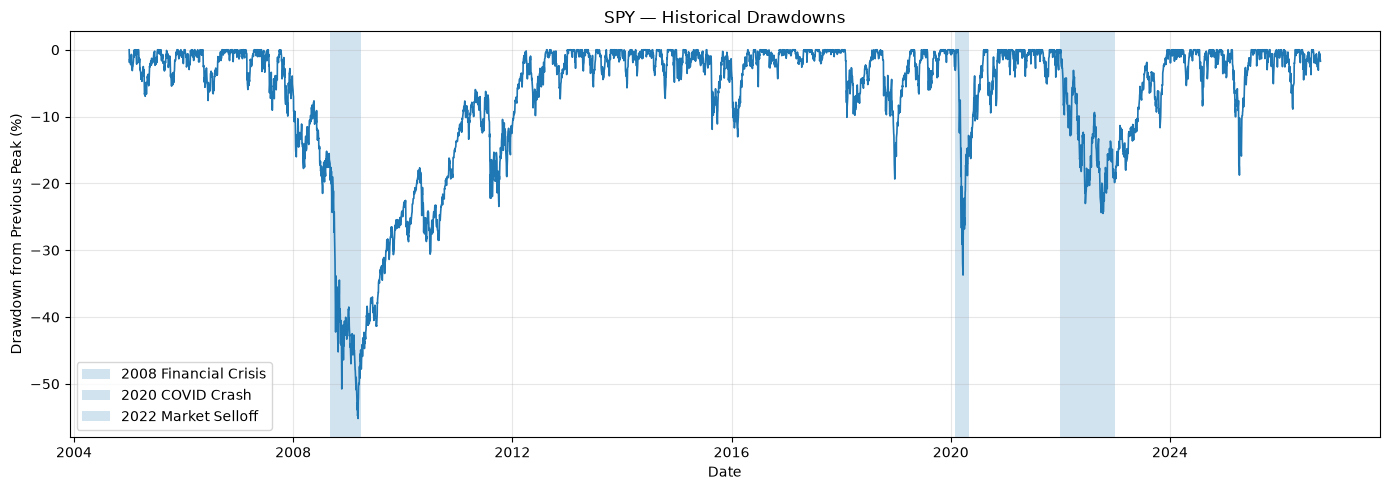

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Calculate drawdown from previous historical peaks
running_peak = prices.cummax()

drawdown = (
    prices / running_peak - 1
) * 100

# Compare historical stress periods
stress_results = []

for name, (start, end) in stress_periods.items():

    period_prices = prices.loc[start:end]
    period_vol = volatility.loc[start:end]
    period_drawdown = drawdown.loc[start:end]

    if period_prices.empty:
        continue

    # Return during the selected period
    total_return = (
        period_prices.iloc[-1] /
        period_prices.iloc[0] - 1
    ) * 100

    stress_results.append({
        "Crisis": name,
        "Period Return (%)": total_return,
        "Peak Volatility (%)": period_vol.max(),
        "Average Volatility (%)": period_vol.mean(),
        "Worst Drawdown (%)": period_drawdown.min()
    })

stress_summary = pd.DataFrame(stress_results)

display(stress_summary.round(2))

# Plot historical drawdowns
plt.figure(figsize=(14, 5))

plt.plot(
    drawdown.index,
    drawdown,
    linewidth=1.2
)

for name, (start, end) in stress_periods.items():
    plt.axvspan(
        pd.Timestamp(start),
        pd.Timestamp(end),
        alpha=0.20,
        label=name
    )

plt.title("SPY — Historical Drawdowns")
plt.xlabel("Date")
plt.ylabel("Drawdown from Previous Peak (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 3b. Crisis resilience score
Measures how well SPY **recovered** from each stress window. Unlike Section 3, these metrics deliberately look **beyond the window end date**, because recovery happens after the crisis.

| Component | Definition | Weight |
|---|---|---|
| **Depth** | Drawdown from pre-crisis peak to in-window trough. 0% → 100 pts, −60% or worse → 0 pts | 30% |
| **Recovery time** | Trading days from trough until price regains the pre-crisis peak, log-scaled. 0 days → 100 pts, 1,260 days (≈5 yrs) or more → 0 pts | 30% |
| **6-month retracement** | Share of the peak-to-trough loss regained 126 trading days after the trough | 20% |
| **Volatility normalization** | Trading days from peak 20-day volatility until it falls within 25% of its pre-crisis median. 0 days → 100 pts, 252+ days → 0 pts | 20% |

- **Pre-crisis peak:** highest close in the 252 trading days before the window start, up to the trough (so the Feb 19, 2020 peak inside the COVID window is captured).
- **Trough:** lowest close inside the window.
- **Fixed anchors** (not min-max across crises) keep scores comparable when crises or tickers are added.
- **Censoring:** if price has not regained the peak by the end of the data, recovery time is measured to the last date and flagged — the score is then an *upper bound*.
- The Ulcer Index (RMS drawdown from peak to recovery) is reported for reference but not scored, since it overlaps depth and duration.

In [5]:
import numpy as np
import pandas as pd

RESILIENCE_WEIGHTS = {
    "Depth": 0.30,
    "Recovery": 0.30,
    "Retracement": 0.20,
    "Vol Normalization": 0.20,
}

def resilience_metrics(prices, vol, start, end,
                       lookback=252, retrace_days=126,
                       vol_tolerance=1.25, vol_baseline_days=60):
    """Descriptive recovery metrics for one price series and stress window."""

    window = prices.loc[start:end]
    if window.empty:
        return None

    idx = prices.index

    # Trough: lowest close inside the window
    trough_date = window.idxmin()
    trough_px = window.min()
    t_pos = idx.get_loc(trough_date)

    # Pre-crisis peak: highest close in lookback before window start, up to trough
    start_pos = idx.get_loc(window.index[0])
    pre = prices.iloc[max(0, start_pos - lookback):t_pos + 1]
    peak_date = pre.idxmax()
    peak_px = pre.max()
    p_pos = idx.get_loc(peak_date)

    max_drawdown = (trough_px / peak_px - 1) * 100

    # Time to recover (uses data after the window)
    after = prices.iloc[t_pos:]
    recovered = after[after >= peak_px]
    censored = recovered.empty
    rec_date = after.index[-1] if censored else recovered.index[0]
    rec_days = idx.get_loc(rec_date) - t_pos

    # 6-month retracement of the peak-to-trough loss
    r_pos = t_pos + retrace_days
    retrace_available = r_pos < len(prices)
    px_later = prices.iloc[min(r_pos, len(prices) - 1)]
    retracement = (px_later - trough_px) / (peak_px - trough_px) * 100

    # Volatility normalization: peak vol -> within tolerance of pre-crisis median
    base_vol = vol.loc[:peak_date].iloc[:-1].tail(vol_baseline_days).median()
    vmax_date = vol.loc[start:end].idxmax()
    calm = vol.loc[vmax_date:]
    calm = calm[calm <= vol_tolerance * base_vol]
    vol_days = (
        np.nan if calm.empty
        else vol.index.get_loc(calm.index[0]) - vol.index.get_loc(vmax_date)
    )

    # Ulcer index over peak -> recovery (reference only)
    path = prices.loc[peak_date:rec_date]
    ulcer = np.sqrt(((path / path.cummax() - 1) * 100).pow(2).mean())

    return {
        "Peak Date": peak_date.date(),
        "Trough Date": trough_date.date(),
        "Recovery Date": None if censored else rec_date.date(),
        "Recovery Censored": censored,
        "Max Drawdown (%)": max_drawdown,
        "Days Peak to Trough": t_pos - p_pos,
        "Days to Recover": rec_days,
        "6M Retracement (%)": retracement,
        "Retracement Complete Window": retrace_available,
        "Pre-Crisis Vol (%)": base_vol,
        "Peak Vol (%)": vol.loc[vmax_date],
        "Vol Normalization Days": vol_days,
        "Ulcer Index": ulcer,
    }


def resilience_components(m):
    """Map raw metrics to fixed 0-100 component scores."""
    vol_days = m["Vol Normalization Days"]
    return {
        "Depth": 100 * np.clip(1 - abs(m["Max Drawdown (%)"]) / 60, 0, 1),
        "Recovery": 100 * np.clip(
            1 - np.log1p(m["Days to Recover"]) / np.log1p(1260), 0, 1
        ),
        "Retracement": 100 * np.clip(m["6M Retracement (%)"] / 100, 0, 1),
        "Vol Normalization": (
            0.0 if pd.isna(vol_days)
            else 100 * np.clip(1 - vol_days / 252, 0, 1)
        ),
    }


def resilience_score(components, weights=RESILIENCE_WEIGHTS):
    return sum(weights[k] * components[k] for k in weights)

In [6]:
resilience_rows = []

for name, (start, end) in stress_periods.items():

    metrics = resilience_metrics(prices, volatility, start, end)
    if metrics is None:
        continue

    components = resilience_components(metrics)

    resilience_rows.append({
        "Crisis": name,
        **metrics,
        **{f"{k} Score": v for k, v in components.items()},
        "Resilience Score": resilience_score(components),
    })

resilience_df = pd.DataFrame(resilience_rows)

display(resilience_df.set_index("Crisis").T.round(2))

if resilience_df["Recovery Censored"].any():
    print("Note: at least one crisis has not recovered by the end of the data;"
          " its recovery score is an upper bound.")

# Add the score to the Section 3 summary table
stress_summary = stress_summary.drop(
    columns="Resilience Score", errors="ignore"
).merge(
    resilience_df[["Crisis", "Resilience Score"]],
    on="Crisis",
    how="left"
)

display(stress_summary.round(2))

Crisis,2008 Financial Crisis,2020 COVID Crash,2022 Market Selloff
Peak Date,2007-10-09,2020-02-19,2022-01-03
Trough Date,2009-03-09,2020-03-23,2022-10-12
Recovery Date,2012-08-16,2020-08-10,2023-12-13
Recovery Censored,False,False,False
Max Drawdown (%),-55.189446,-33.717269,-24.496392
Days Peak to Trough,355,23,195
Days to Recover,869,97,294
6M Retracement (%),42.034799,94.146453,51.326269
Retracement Complete Window,True,True,True
Pre-Crisis Vol (%),18.482987,7.473568,14.655666


,Crisis,Period Return (%),Peak Volatility (%),Average Volatility (%),Worst Drawdown (%),Resilience Score
0,2008 Financial Crisis,-36.55,93.97,51.65,-55.19,20.31
1,2020 COVID Crash,-9.85,93.92,50.56,-33.72,54.61
2,2022 Market Selloff,-18.65,35.41,23.72,-24.50,50.55


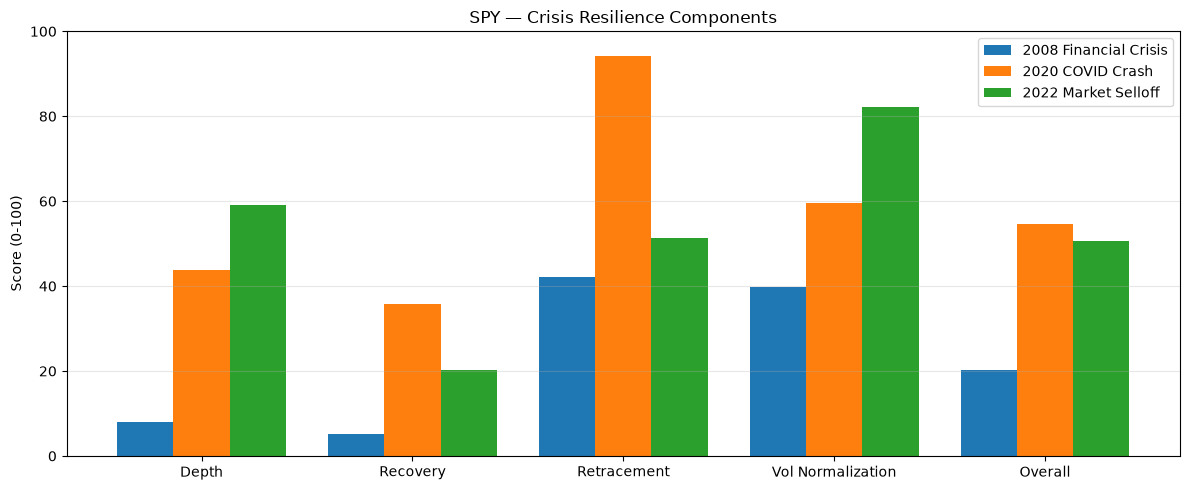

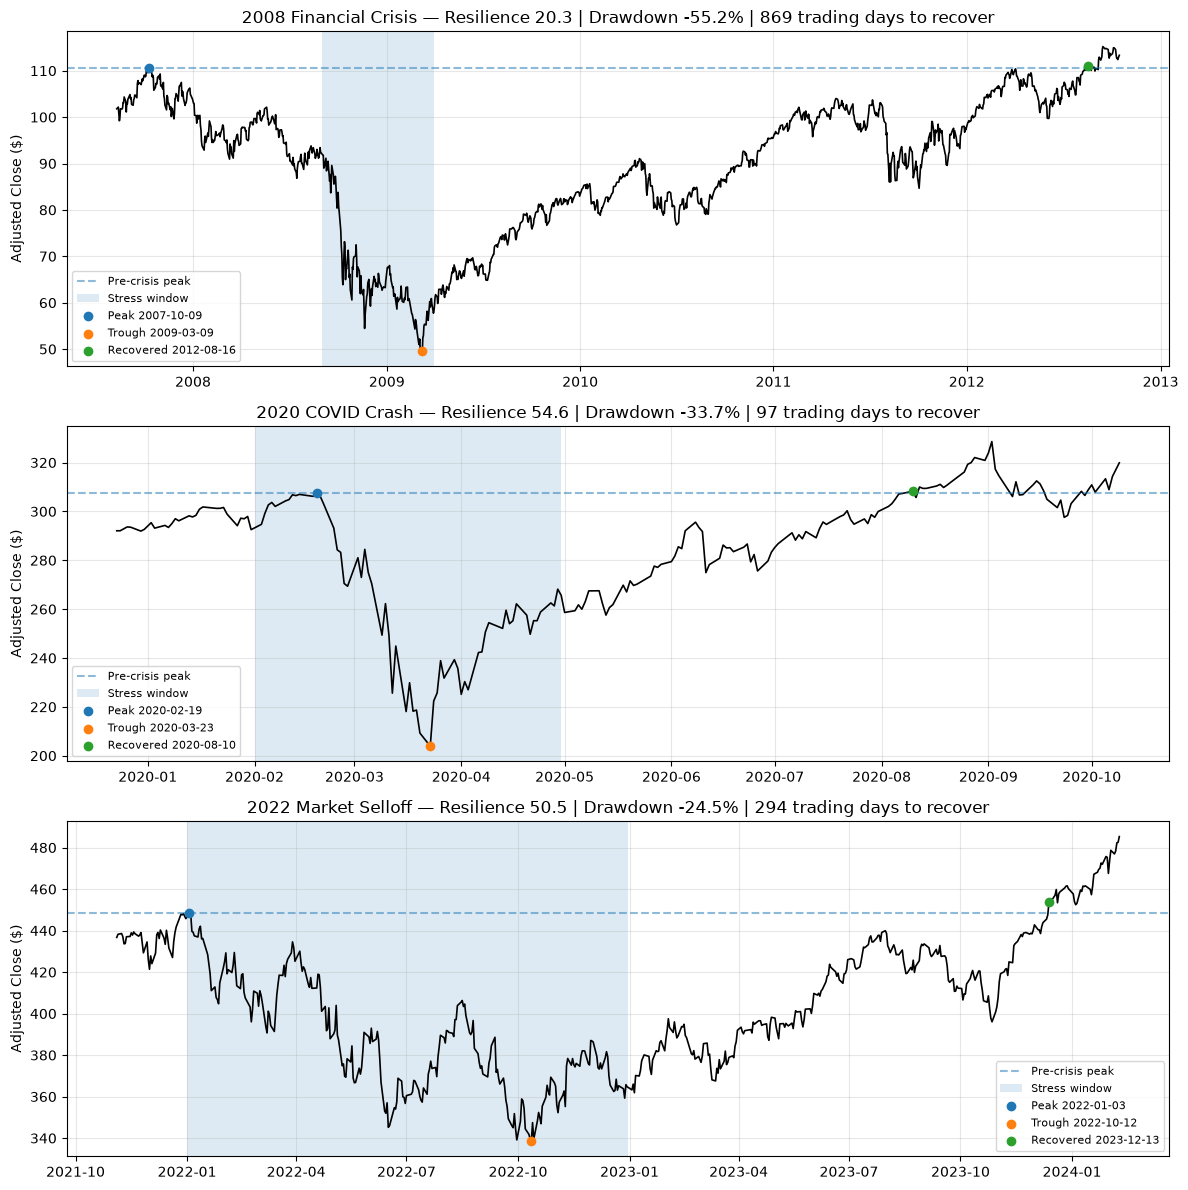

In [7]:
import matplotlib.pyplot as plt

component_names = list(RESILIENCE_WEIGHTS)

# --- Component scores by crisis ---
fig, ax = plt.subplots(figsize=(12, 5))

bar_width = 0.8 / len(resilience_df)
x = np.arange(len(component_names) + 1)

for i, row in resilience_df.reset_index(drop=True).iterrows():
    values = [row[f"{c} Score"] for c in component_names] + [row["Resilience Score"]]
    ax.bar(x + i * bar_width, values, width=bar_width, label=row["Crisis"])

ax.set_xticks(x + bar_width * (len(resilience_df) - 1) / 2)
ax.set_xticklabels(component_names + ["Overall"])
ax.set_ylim(0, 100)
ax.set_ylabel("Score (0-100)")
ax.set_title("SPY — Crisis Resilience Components")
ax.legend()
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

# --- Price paths: peak -> trough -> recovery ---
fig, axes = plt.subplots(len(resilience_df), 1, figsize=(12, 4 * len(resilience_df)))
axes = np.atleast_1d(axes)

for ax, (_, row) in zip(axes, resilience_df.iterrows()):

    peak = pd.Timestamp(row["Peak Date"])
    trough = pd.Timestamp(row["Trough Date"])
    recovery = (
        prices.index[-1] if row["Recovery Censored"]
        else pd.Timestamp(row["Recovery Date"])
    )

    pad = pd.Timedelta(days=60)
    segment = prices.loc[peak - pad:recovery + pad]

    ax.plot(segment.index, segment, color="black", linewidth=1.2)
    ax.axhline(prices.loc[peak], linestyle="--", alpha=0.5, label="Pre-crisis peak")

    start, end = stress_periods[row["Crisis"]]
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), alpha=0.15, label="Stress window")

    ax.scatter([peak], [prices.loc[peak]], zorder=3, label=f"Peak {peak.date()}")
    ax.scatter([trough], [prices.loc[trough]], zorder=3, label=f"Trough {trough.date()}")
    rec_label = "Not recovered" if row["Recovery Censored"] else f"Recovered {recovery.date()}"
    ax.scatter([recovery], [prices.loc[recovery]], zorder=3, label=rec_label)

    ax.set_title(
        f"{row['Crisis']} — Resilience {row['Resilience Score']:.1f} | "
        f"Drawdown {row['Max Drawdown (%)']:.1f}% | "
        f"{row['Days to Recover']} trading days to recover"
    )
    ax.set_ylabel("Adjusted Close ($)")
    ax.legend(fontsize=8, loc="best")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Rolling GARCH(1,1) forecasts
Refit GARCH using returns available through each forecast date. Compare the next five trading days’ mean squared returns to expected squared returns. Forecasts at the end of a selected crisis window can have realized outcomes beyond the window.

In [8]:
from arch import arch_model
import numpy as np
import pandas as pd

# Daily returns in percentage units
returns_pct = returns * 100

HORIZON = 5

garch_stress_results = []

for crisis, (start, end) in stress_periods.items():

    print(f"Evaluating {crisis}...")

    # Forecast dates within the crisis
    crisis_dates = returns_pct.loc[start:end].index

    # Use every fifth trading day
    forecast_dates = crisis_dates[::HORIZON]

    for date in forecast_dates:

        # Use historical information through forecast date
        history = returns_pct.loc[:date]

        if len(history) < 250:
            continue

        # Fit GARCH using past information
        model = arch_model(
            history,
            mean="Constant",
            vol="GARCH",
            p=1,
            q=1,
            dist="t"
        )

        fit = model.fit(
            disp="off",
            show_warning=False
        )

        # Forecast five-day conditional variance
        forecast = fit.forecast(horizon=HORIZON)

        daily_var = (
            forecast.variance.iloc[-1].to_numpy()
        )

        daily_mean = (
            forecast.mean.iloc[-1].to_numpy()
        )

        predicted_var = np.mean(
            daily_var + daily_mean**2
        )

        # Actual next five trading days
        position = returns_pct.index.get_loc(date)

        future = returns_pct.iloc[
            position + 1:position + 1 + HORIZON
        ]

        if len(future) < HORIZON:
            continue

        actual_var = np.mean(
            future.to_numpy()**2
        )

        garch_stress_results.append({
            "Crisis": crisis,
            "Date": date,
            "GARCH_Vol": np.sqrt(
                predicted_var * 252
            ),
            "Actual_Vol": np.sqrt(
                actual_var * 252
            )
        })

garch_stress_df = pd.DataFrame(
    garch_stress_results
)

display(garch_stress_df.head())

print(
    "Total crisis forecasts:",
    len(garch_stress_df)
)

Evaluating 2008 Financial Crisis...
Evaluating 2020 COVID Crash...
Evaluating 2022 Market Selloff...


,Crisis,Date,GARCH_Vol,Actual_Vol
0,2008 Financial Crisis,2008-09-02,18.506884,33.833867
1,2008 Financial Crisis,2008-09-09,25.490592,38.207838
2,2008 Financial Crisis,2008-09-16,31.318589,52.851672
3,2008 Financial Crisis,2008-09-23,40.514619,65.664055
4,2008 Financial Crisis,2008-09-30,53.435913,56.717032


Total crisis forecasts: 94


## 5. Pre-crisis XGBoost forecasts
Train a fixed XGBoost model separately before each stress window, purging overlapping five-day targets. GARCH refits within the window, but XGBoost does not; these are **different update policies**. The hyperparameters were selected retrospectively in earlier project work.

In [9]:
import numpy as np
import pandas as pd
from xgboost import XGBRegressor

HORIZON = 5
EPSILON = 1e-6

# Daily returns in percentage units
r = returns * 100

# Build historical features
features = pd.DataFrame(index=r.index)

for window in [5, 10, 20, 60]:

    features[f"var_{window}d"] = (
        r.pow(2).rolling(window).mean()
    )

    features[f"return_{window}d"] = (
        r.rolling(window).sum()
    )

features["abs_return_1d"] = r.abs()
features["return_1d"] = r
features["negative_return_1d"] = (
    r < 0
).astype(int)

# Future five-day realized variance
future = pd.concat(
    [
        r.shift(-i).pow(2)
        for i in range(1, HORIZON + 1)
    ],
    axis=1
)

features["target"] = future.mean(axis=1)
features.loc[
    features.index[-HORIZON:], "target"
] = np.nan

feature_cols = [
    c for c in features.columns if c != "target"
]

dataset = features.dropna()

xgb_stress_results = []

for crisis, (start, end) in stress_periods.items():

    print(f"Training XGBoost for {crisis}...")

    # Find first crisis observation
    crisis_start = dataset.index.searchsorted(
        pd.Timestamp(start)
    )

    # Purge five-day target overlap
    train = dataset.iloc[
        :max(0, crisis_start - HORIZON)
    ]

    if len(train) < 250:
        print(f"Insufficient training data: {crisis}")
        continue

    # Selected Very Simple XGBoost model
    model = XGBRegressor(
        n_estimators=50,
        max_depth=2,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=10,
        min_child_weight=10,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=2
    )

    model.fit(
        train[feature_cols],
        np.log(train["target"] + EPSILON)
    )

    # Use the exact same dates as GARCH
    crisis_forecasts = garch_stress_df[
        garch_stress_df["Crisis"] == crisis
    ]

    for _, row in crisis_forecasts.iterrows():

        date = row["Date"]

        X = features.loc[
            [date], feature_cols
        ]

        predicted_log_var = model.predict(X)[0]

        predicted_var = max(
            np.exp(predicted_log_var) - EPSILON,
            1e-8
        )

        xgb_vol = np.sqrt(
            predicted_var * 252
        )

        xgb_stress_results.append({
            "Crisis": crisis,
            "Date": date,
            "XGBoost_Vol": xgb_vol
        })

xgb_stress_df = pd.DataFrame(
    xgb_stress_results
)

# Combine predictions on identical dates
crisis_comparison = garch_stress_df.merge(
    xgb_stress_df,
    on=["Crisis", "Date"],
    how="inner"
)

print(
    "\nForecasts compared:",
    len(crisis_comparison)
)

display(crisis_comparison.head())

XGBoostError: 
XGBoost Library (libxgboost.dylib) could not be loaded.
Likely causes:
  * OpenMP runtime is not installed
    - vcomp140.dll or libgomp-1.dll for Windows
    - libomp.dylib for Mac OSX
    - libgomp.so for Linux and other UNIX-like OSes
    Mac OSX users: Run `brew install libomp` to install OpenMP runtime.

  * You are running 32-bit Python on a 64-bit OS

Error message(s): ["dlopen(/Users/madisenjohnson/venvs/ramses/lib/python3.12/site-packages/xgboost/lib/libxgboost.dylib, 0x0006): Library not loaded: @rpath/libomp.dylib\n  Referenced from: <09B43001-8527-34F6-AAE4-B97DA8A6CBC0> /Users/madisenjohnson/venvs/ramses/lib/python3.12/site-packages/xgboost/lib/libxgboost.dylib\n  Reason: tried: '/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/homebrew/opt/libomp/lib/li

## 6. Historical baseline and final accuracy comparison
Evaluate all three methods on identical dates using annualized volatility MAE, RMSE, and signed bias. Lower MAE/RMSE and bias closer to zero are preferred.

In [10]:
import numpy as np
import pandas as pd

# Add historical baseline on the same forecast dates
crisis_comparison["Baseline_Vol"] = np.nan

for i, row in crisis_comparison.iterrows():

    date = row["Date"]

    # Only returns available through forecast date
    history = returns_pct.loc[:date]

    # Historical mean squared returns
    baseline_var = (
        history.iloc[-20:].pow(2).mean()
    )

    crisis_comparison.loc[i, "Baseline_Vol"] = (
        np.sqrt(baseline_var * 252)
    )

# Compare all three models
final_results = []

for crisis, group in crisis_comparison.groupby("Crisis"):

    actual = group["Actual_Vol"].to_numpy()

    for model in ["Baseline", "GARCH", "XGBoost"]:

        predicted = group[f"{model}_Vol"].to_numpy()

        final_results.append({
            "Crisis": crisis,
            "Model": model,
            "MAE": np.mean(np.abs(predicted - actual)),
            "RMSE": np.sqrt(
                np.mean((predicted - actual)**2)
            ),
            "Bias": np.mean(predicted - actual)
        })

final_crisis_results = pd.DataFrame(final_results)

display(
    final_crisis_results.sort_values(
        ["Crisis", "MAE"]
    ).round(2)
)

NameError: name 'crisis_comparison' is not defined

## 6b. Resilience vs. forecast error
Places each crisis's resilience score next to model MAE and bias. With only three crises this is descriptive, not a statistical test; it shows whether forecasting was harder (or more biased) in crises that recovered slowly.

In [ ]:
error_wide = final_crisis_results.pivot(
    index="Crisis", columns="Model", values=["MAE", "Bias"]
)
error_wide.columns = [f"{model} {metric}" for metric, model in error_wide.columns]

resilience_vs_error = (
    resilience_df.set_index("Crisis")[
        ["Resilience Score", "Max Drawdown (%)", "Days to Recover"]
    ]
    .join(error_wide)
    .sort_values("Resilience Score", ascending=False)
)

display(resilience_vs_error.round(2))

## 7. Forecast trajectories
Compare realized volatility against GARCH and XGBoost throughout each stress period.

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    3, 1,
    figsize=(12, 12)
)

for ax, (crisis, group) in zip(
    axes,
    crisis_comparison.groupby("Crisis", sort=False)
):

    ax.plot(
        group["Date"],
        group["Actual_Vol"],
        label="Actual Volatility",
        color="black",
        linewidth=2
    )

    ax.plot(
        group["Date"],
        group["GARCH_Vol"],
        label="GARCH",
        linewidth=1.8
    )

    ax.plot(
        group["Date"],
        group["XGBoost_Vol"],
        label="XGBoost",
        linewidth=1.8
    )

    ax.set_title(crisis)
    ax.set_ylabel("Annualized Volatility (%)")
    ax.legend()
    ax.grid(alpha=0.3)

plt.xlabel("Forecast Date")
plt.tight_layout()
plt.show()

## 8. Interactive crisis explorer
Choose a stress window to view all three forecasting methods the corresponding accuracy table, and its resilience metrics.

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import matplotlib.pyplot as plt

# Interactive crisis selection
crisis_selector = widgets.Dropdown(
    options=list(crisis_comparison["Crisis"].unique()),
    description="Crisis:"
)

output = widgets.Output()

def update_crisis(change=None):

    with output:
        clear_output(wait=True)

        selected = crisis_selector.value

        group = crisis_comparison[
            crisis_comparison["Crisis"] == selected
        ].sort_values("Date")

        plt.figure(figsize=(11, 5))

        plt.plot(
            group["Date"],
            group["Actual_Vol"],
            label="Actual Volatility",
            color="black",
            linewidth=2
        )

        for model in ["Baseline", "GARCH", "XGBoost"]:

            plt.plot(
                group["Date"],
                group[f"{model}_Vol"],
                label=model,
                linewidth=1.8
            )

        plt.title(selected + " — Volatility Forecast Comparison")
        plt.xlabel("Date")
        plt.ylabel("Annualized Volatility (%)")
        plt.legend()
        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()

        # Show accuracy for selected crisis
        display(
            final_crisis_results[
                final_crisis_results["Crisis"] == selected
            ].sort_values("MAE").round(2)
        )

        # Show resilience for selected crisis
        display(
            resilience_df[
                resilience_df["Crisis"] == selected
            ].set_index("Crisis").T.round(2)
        )

crisis_selector.observe(
    update_crisis,
    names="value"
)

display(crisis_selector, output)

update_crisis()

## Methodology and limitations

- **Data:** Adjusted SPY closing prices downloaded from Yahoo Finance for 2005-01-01 to 2026-10-01 (end date exclusive). Downloaded data may change; record the run date.
- **Target:** Next five trading days’ average squared daily log returns (in percent units), displayed as annualized volatility using $\sqrt{252\,\mathrm{mean}(r^2)}$.
- **Historical baseline:** Previous 20 trading days’ mean squared returns.
- **GARCH:** Constant-mean GARCH(1,1) with Student-t innovations, refitted at each forecast date.
- **XGBoost:** Fixed pre-crisis log-variance regression, with features and hyperparameters inherited from Feature 1.
- **Resilience score:** Weighted sum (30% depth, 30% recovery time, 20% six-month retracement, 20% volatility normalization) of fixed-anchor 0–100 component scores. It is descriptive and uses prices after each window, so it must not be used as a forecasting feature (look-ahead). Weights and anchors are judgment calls; unrecovered crises are flagged as censored.
- **Cautions:** This is an exploratory retrospective comparison. The selected model settings reflect later development; model update schedules differ; results cover selected SPY crisis windows only. This notebook does not backtest historical option prices or hedging P&L. Five-day forecast windows are selected approximately nonoverlapping within each crisis.
- **Submission check:** Run all cells from a fresh Colab runtime and verify the charts, forecast counts, and metrics before submission.